# Seven-dataset L1 / L12 / L2 cell counts (pan-cancer Hist2Pheno)

Joint training uses sheet `celltype_pancancer` in [`PanCancerCellType.xlsx`](PanCancerCellType.xlsx).
Xenium lung is treated as a cancer cohort here (IPF atlas).

**Heads**

| Head | Role on H&E |
|------|-------------|
| **L1** | Lineage a pathologist can name by eye (Epithelial / Immune / Stromal / Endothelial / Neural) |
| **L12** | Batch-identification aid (Tumor vs residual epithelium; T vs B/Plasma vs Myeloid; …) |
| **L2** | States not reliably split on H&E (CD4 vs CD8, Treg, NK, mac states, …) |

**Dropped before training**

1. The entire `Other` row (`Unknown` / `Unlabeled` / `Other` / `Stroma Uncharacterized` / `LowQ`).
2. Natives in `dropped_aliases` — unlabeled/rare **or** morphologically far from the L2 name (mast ≠ neutrophil, adipocyte ≠ CAF, unspecified T ≠ NK, …).

Counts are the cells in `data/PanCancer/section_index.csv`: 896 sections, the same set UNI2 A2 trained on. Kept L1 / L12 / L2 labels are read from each section's `label_cache` npz (5,627,071 cells). `n_drop` is what the pan-cancer filter removed before training; those natives are not stored in the cache. An older count built from the raw annotation tables is not used.


In [1]:
from __future__ import annotations

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

try:
    from IPython.display import display
except ImportError:
    def display(obj):
        print(obj.to_string() if hasattr(obj, "to_string") else obj)

HERE = Path(".").resolve()
if not (HERE / "PanCancerCellType.xlsx").exists():
    HERE = Path("/home/lingyu/ssd2/Python/Hist2Pheno/code/Hist2Pheno_pkg/dataset")
REPO = HERE.parents[2]
XLSX = HERE / "PanCancerCellType.xlsx"
FIG = HERE / "figures_pancancer_counts"
FIG.mkdir(exist_ok=True)

if str(HERE) not in sys.path:
    sys.path.insert(0, str(HERE))
from build_pancancer_celltype_v1 import (  # noqa: E402
    L1_ORDER,
    L12_ORDER,
    NATIVE_TO_V1,
    pancancer_drop_reason,
    pancancer_keeps_native,
    unified_of,
    _strip,
)

DATASETS = ["Lung", "BRCA", "HCC", "PDAC", "GIST", "GBM", "CRC"]
DS_COLOR = {
    "Lung": "#7f8c8d",
    "BRCA": "#c0392b",
    "HCC": "#d35400",
    "PDAC": "#1e8449",
    "GIST": "#2471a3",
    "GBM": "#6c3483",
    "CRC": "#117a65",
}
L1_COLOR = {
    "Epithelial": "#E67E22",
    "Immune": "#2E86C1",
    "Stromal": "#27AE60",
    "Endothelial": "#B7950B",
    "Neural": "#8E44AD",
    "dropped": "#bdc3c7",
}
L12_COLOR = {
    "Tumor": "#d35400",
    "Epithelial": "#E67E22",
    "T_cell": "#2980b9",
    "B_Plasma": "#8e44ad",
    "Myeloid": "#16a085",
    "Stromal": "#27AE60",
    "Endothelial": "#B7950B",
    "Neural": "#6c3483",
}

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 180,
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

pc = pd.read_excel(XLSX, "celltype_pancancer")
print(XLSX, "exists=", XLSX.exists())
print("celltype_pancancer trainable L2 =", int((pc["trainable"] == "Y").sum()))
display(pc[["L1", "L12", "L2", "L2_aliases", "dropped_aliases", "present_in"]].reset_index(drop=True))


/nobackup2/users/lingyu/Python/Hist2Pheno/code/Hist2Pheno_pkg/dataset/PanCancerCellType.xlsx exists= True
celltype_pancancer trainable L2 = 20


,L1,L12,L2,L2_aliases,dropped_aliases,present_in
0,Epithelial,Tumor,DCIS,DCIS_1; DCIS_2,NaN,BRCA
1,Epithelial,Tumor,Tumor,AC-like; Epithelium (INOS+); Epithelium (INOS-...,T_Cell_&_Tumor_Hybrid,BRCA; HCC; GBM; CRC
2,Epithelial,Epithelial,Alveolar,AT1; AT2; Proliferating AT2,NaN,Lung
3,Epithelial,Epithelial,Epithelial,Basal; Enterocyte; Epithelial cells; Goblet; M...,Mesothelial; Neuroendocrine; PNEC; Tuft,Lung; PDAC; GIST; CRC
4,Epithelial,Epithelial,Injury_epithelial,KRT5-/KRT17+; RASC; Transitional AT2,NaN,Lung
5,Epithelial,Epithelial,Myoepithelial,Myoepi_ACTA2+; Myoepi_KRT15+,NaN,BRCA
6,Immune,T_cell,CD4_T,CD4 T cell; CD4 T cells; CD4+ T-cells; CD4+_T_...,NaN,Lung; BRCA; HCC; PDAC; GIST; CRC
7,Immune,T_cell,CD8_T,CD8 T cell; CD8 T cells; CD8+ T-cells; CD8+_T_...,NaN,Lung; BRCA; HCC; PDAC; CRC
8,Immune,T_cell,Tregs,Treg; Tregs,NaN,Lung; PDAC; GIST
9,Immune,T_cell,NK,NK; NK/NKT; Proliferating NK/NKT,INFg+; Lymphocyte; Proliferating T-cells; T cells,Lung; CRC


## 1. Native label → pan-cancer head

Each GT cell is mapped with `NATIVE_TO_V1`. Status is `kept` only if the native is in `celltype_pancancer.L2_aliases` (equivalently `pancancer_keeps_native`).


In [2]:

def counts_from_section_index() -> pd.DataFrame:
    """Kept labels from the pan-cancer label cache used by UNI2 A2.

    ``section_index.csv`` lists the 896 training sections. Each npz stores
    only the cells that passed ``celltype_pancancer`` (``y_l1``, ``y_l12``, ``y``).
    """
    index_path = REPO / "data/PanCancer/section_index.csv"
    index = pd.read_csv(index_path)
    index = index.loc[index["ok"].astype(str).str.lower().isin(["true", "1"])].copy()
    print(f"section_index {index_path}")
    print(
        f"  {len(index)} sections, n_keep={int(index.n_keep.sum()):,}, "
        f"n_drop={int(index.n_drop.sum()):,}"
    )
    rows = []
    for i, rec in enumerate(index.itertuples(index=False), 1):
        cache = Path(rec.label_cache)
        if not cache.is_file():
            raise FileNotFoundError(cache)
        stored = np.load(cache, allow_pickle=True)
        frame = pd.DataFrame({
            "L1": stored["y_l1"].astype(str),
            "L12": stored["y_l12"].astype(str),
            "L2": stored["y"].astype(str),
        })
        grouped = frame.groupby(["L1", "L12", "L2"], sort=False).size()
        for (l1, l12, l2), n in grouped.items():
            rows.append({
                "dataset": rec.dataset,
                "native": l2,
                "L1": l1,
                "L12": l12,
                "L2": l2,
                "status": "kept",
                "drop_reason": "",
                "n": int(n),
            })
        if int(rec.n_drop) > 0:
            rows.append({
                "dataset": rec.dataset,
                "native": "",
                "L1": pd.NA,
                "L12": pd.NA,
                "L2": pd.NA,
                "status": "dropped",
                "drop_reason": "removed before training",
                "n": int(rec.n_drop),
            })
        if i % 200 == 0 or i == len(index):
            print(f"  {i}/{len(index)} sections", flush=True)
    return pd.DataFrame(rows)


COUNT_CACHE = FIG / "section_index_label_counts.csv"
index_path = REPO / "data/PanCancer/section_index.csv"
rebuild = (not COUNT_CACHE.exists()) or (COUNT_CACHE.stat().st_mtime < index_path.stat().st_mtime)
if rebuild:
    counts = counts_from_section_index()
    counts.to_csv(COUNT_CACHE, index=False)
    print("wrote", COUNT_CACHE)
else:
    counts = pd.read_csv(COUNT_CACHE)
    print("loaded", COUNT_CACHE, "rows", len(counts), "cells", int(counts.n.sum()))

counts["dataset"] = pd.Categorical(counts["dataset"], DATASETS, ordered=True)
print(counts.groupby(["dataset", "status"], observed=True)["n"].sum().unstack(fill_value=0).to_string())


section_index /nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/section_index.csv
  896 sections, n_keep=5,627,071, n_drop=214,682
  200/896 sections
  400/896 sections
  600/896 sections
  800/896 sections
  896/896 sections
wrote /nobackup2/users/lingyu/Python/Hist2Pheno/code/Hist2Pheno_pkg/dataset/figures_pancancer_counts/section_index_label_counts.csv
status   dropped     kept
dataset                  
Lung       59650   578077
BRCA         299   264196
HCC        33648  1059094
PDAC           0  1393006
GIST       91400  1693169
GBM         4194   171016
CRC        25491   468513


## 2. Kept vs dropped per dataset


status,kept,dropped,total,kept_frac
dataset,,,,
Lung,578077.0,59650.0,637727.0,0.906465
BRCA,264196.0,299.0,264495.0,0.998870
HCC,1059094.0,33648.0,1092742.0,0.969208
PDAC,1393006.0,0.0,1393006.0,1.000000
GIST,1693169.0,91400.0,1784569.0,0.948783
GBM,171016.0,4194.0,175210.0,0.976063
CRC,468513.0,25491.0,494004.0,0.948399


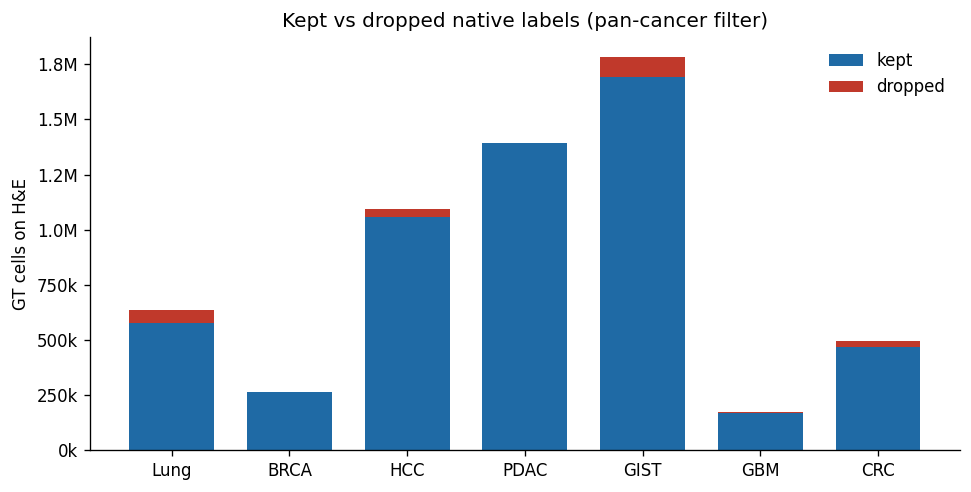

Dropped cells are section_index n_drop. The label cache does not keep their native names.


,dataset,n_drop
0,Lung,59650
1,BRCA,299
2,HCC,33648
3,PDAC,0
4,GIST,91400
5,GBM,4194
6,CRC,25491


In [3]:
status_order = ["kept", "dropped", "unmapped", "empty"]
pivot_status = (
    counts.groupby(["dataset", "status"], observed=True)["n"].sum()
    .unstack("status")
    .reindex(DATASETS)
    .reindex(columns=[c for c in status_order if c in set(counts["status"])], fill_value=0)
    .fillna(0)
)
pivot_status["total"] = pivot_status.sum(axis=1)
pivot_status["kept_frac"] = pivot_status.get("kept", 0) / pivot_status["total"]
display(pivot_status)

fig, ax = plt.subplots(figsize=(8.2, 4.2))
bottom = np.zeros(len(DATASETS))
for st, color in [("kept", "#1f6aa5"), ("dropped", "#c0392b"), ("unmapped", "#7f8c8d")]:
    if st not in pivot_status.columns:
        continue
    vals = pivot_status[st].to_numpy(dtype=float)
    ax.bar(DATASETS, vals, bottom=bottom, color=color, label=st, width=0.72)
    bottom += vals
ax.set_ylabel("GT cells on H&E")
ax.set_title("Kept vs dropped native labels (pan-cancer filter)")
ax.legend(frameon=False)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x/1e6:.1f}M" if x >= 1e6 else f"{x/1e3:.0f}k"))
fig.tight_layout()
fig.savefig(FIG / "01_kept_vs_dropped.png", bbox_inches="tight", facecolor="white")
plt.show()

print("Dropped cells are section_index n_drop. The label cache does not keep their native names.")
drop_tbl = (
    counts.loc[counts.status == "dropped"]
    .groupby("dataset", observed=True)["n"].sum()
    .reindex(DATASETS)
    .fillna(0)
    .astype(int)
    .rename("n_drop")
    .reset_index()
)
display(drop_tbl)


## 3. L1 cell counts (kept only)


L1,Epithelial,Immune,Stromal,Endothelial,Neural,total
dataset,,,,,,
Lung,122354,235033,117949,102741,0,578077
BRCA,115279,58279,75730,14908,0,264196
HCC,386074,506453,94822,71745,0,1059094
PDAC,294841,730377,255830,111958,0,1393006
GIST,130515,996184,444591,121879,0,1693169
GBM,122909,27196,8311,2996,9604,171016
CRC,357530,39560,51359,18820,1244,468513


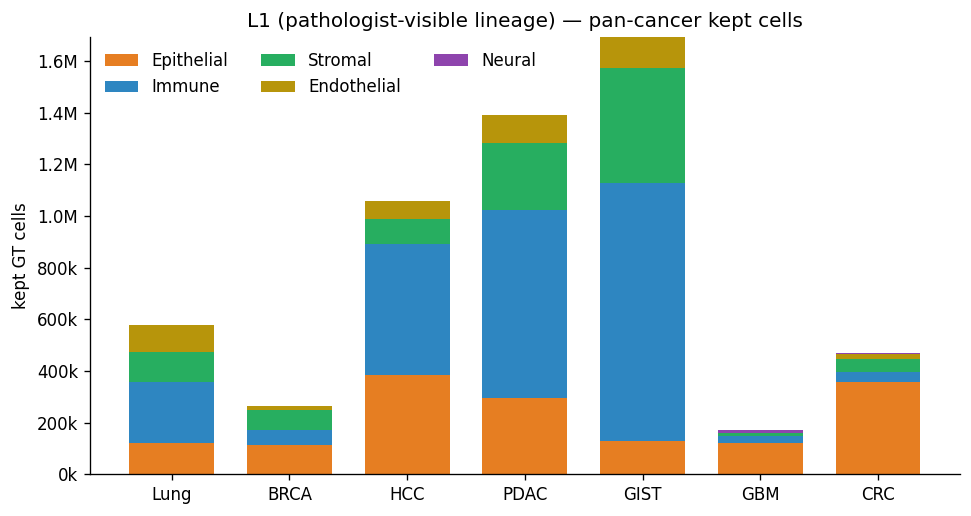

In [4]:
kept = counts[counts.status == "kept"].copy()
l1 = (
    kept.groupby(["dataset", "L1"], observed=True)["n"].sum()
    .unstack("L1")
    .reindex(index=DATASETS, columns=L1_ORDER)
    .fillna(0)
)
l1["total"] = l1.sum(axis=1)
display(l1.astype(int))

fig, ax = plt.subplots(figsize=(8.2, 4.4))
bottom = np.zeros(len(DATASETS))
for lab in L1_ORDER:
    vals = l1[lab].to_numpy(dtype=float)
    ax.bar(DATASETS, vals, bottom=bottom, color=L1_COLOR[lab], label=lab, width=0.72)
    bottom += vals
ax.set_ylabel("kept GT cells")
ax.set_title("L1 (pathologist-visible lineage) — pan-cancer kept cells")
ax.legend(frameon=False, ncol=3, loc="upper left")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x/1e6:.1f}M" if x >= 1e6 else f"{x/1e3:.0f}k"))
fig.tight_layout()
fig.savefig(FIG / "02_L1_counts.png", bbox_inches="tight", facecolor="white")
plt.show()


## 4. L12 cell counts (kept only)


L12,Tumor,Epithelial,T_cell,B_Plasma,Myeloid,Stromal,Endothelial,Neural,total
dataset,,,,,,,,,
Lung,0,122354,74366,40367,120300,117949,102741,0,578077
BRCA,97269,18010,26256,8656,23367,75730,14908,0,264196
HCC,386074,0,204205,26124,276124,94822,71745,0,1059094
PDAC,0,294841,415084,68995,246298,255830,111958,0,1393006
GIST,0,130515,488630,34576,472978,444591,121879,0,1693169
GBM,122909,0,0,0,27196,8311,2996,9604,171016
CRC,276127,81403,7095,18347,14118,51359,18820,1244,468513


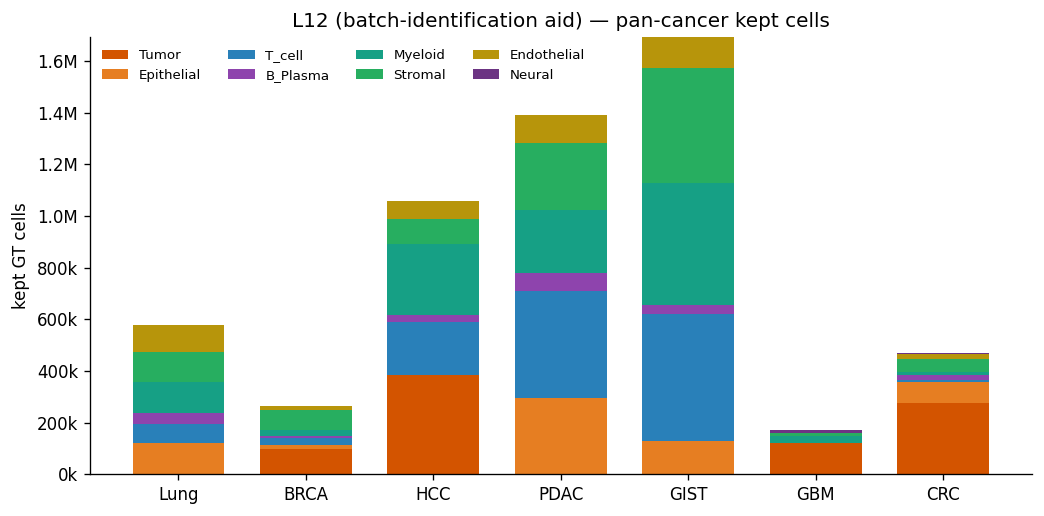

In [5]:
l12 = (
    kept.groupby(["dataset", "L12"], observed=True)["n"].sum()
    .unstack("L12")
    .reindex(index=DATASETS, columns=L12_ORDER)
    .fillna(0)
)
l12["total"] = l12.sum(axis=1)
display(l12.astype(int))

fig, ax = plt.subplots(figsize=(8.8, 4.4))
bottom = np.zeros(len(DATASETS))
for lab in L12_ORDER:
    vals = l12[lab].to_numpy(dtype=float)
    ax.bar(DATASETS, vals, bottom=bottom, color=L12_COLOR[lab], label=lab, width=0.72)
    bottom += vals
ax.set_ylabel("kept GT cells")
ax.set_title("L12 (batch-identification aid) — pan-cancer kept cells")
ax.legend(frameon=False, ncol=4, loc="upper left", fontsize=8)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x/1e6:.1f}M" if x >= 1e6 else f"{x/1e3:.0f}k"))
fig.tight_layout()
fig.savefig(FIG / "03_L12_counts.png", bbox_inches="tight", facecolor="white")
plt.show()


## 5. L2 cell counts (kept only)

Rows follow `celltype_pancancer`. A blank cell means that L2 is absent after the pan-cancer filter (`present_in`).


dataset,Lung,BRCA,HCC,PDAC,GIST,GBM,CRC,total
L2,,,,,,,,
DCIS,0,41775,0,0,0,0,0,41775
Tumor,0,55494,386074,0,0,122909,276127,840604
Alveolar,58050,0,0,0,0,0,0,58050
Epithelial,50214,0,0,294841,130515,0,81403,556973
Injury_epithelial,14090,0,0,0,0,0,0,14090
Myoepithelial,0,18010,0,0,0,0,0,18010
CD4_T,36133,14388,94856,127936,175826,0,5783,454922
CD8_T,21016,11868,109349,283404,0,0,1283,426920
Tregs,5591,0,0,3744,312804,0,0,322139


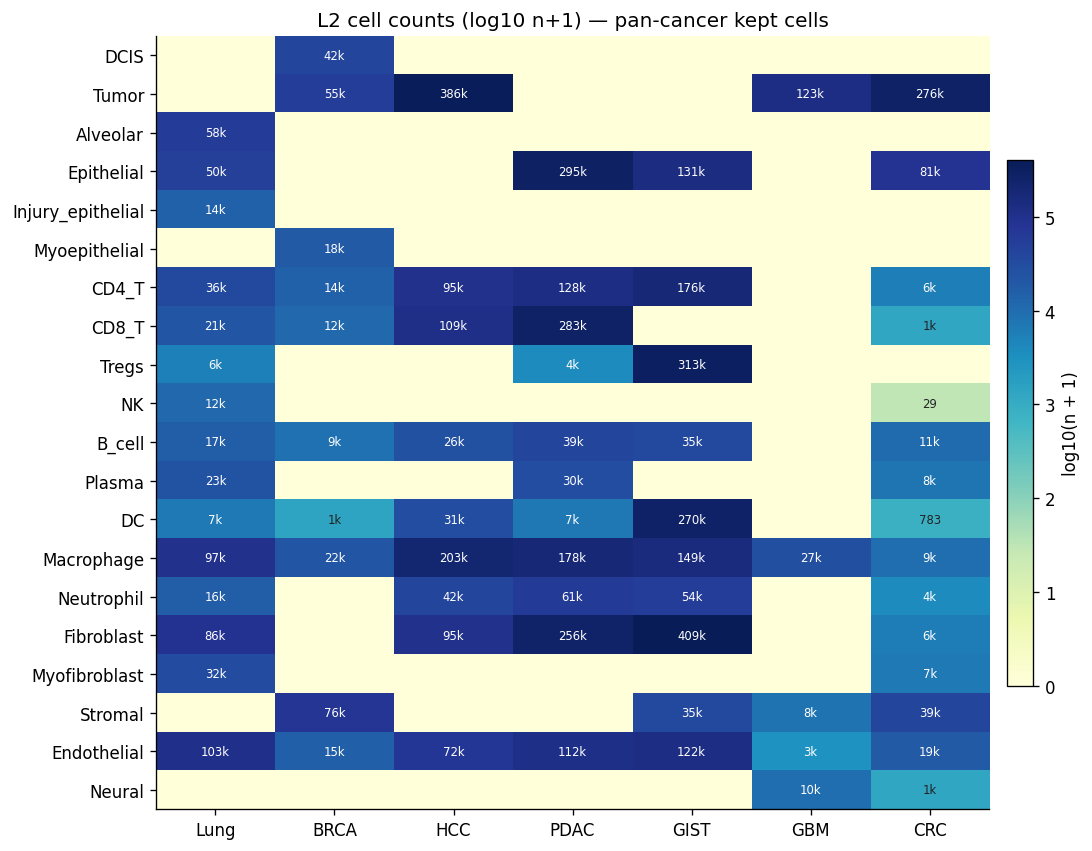

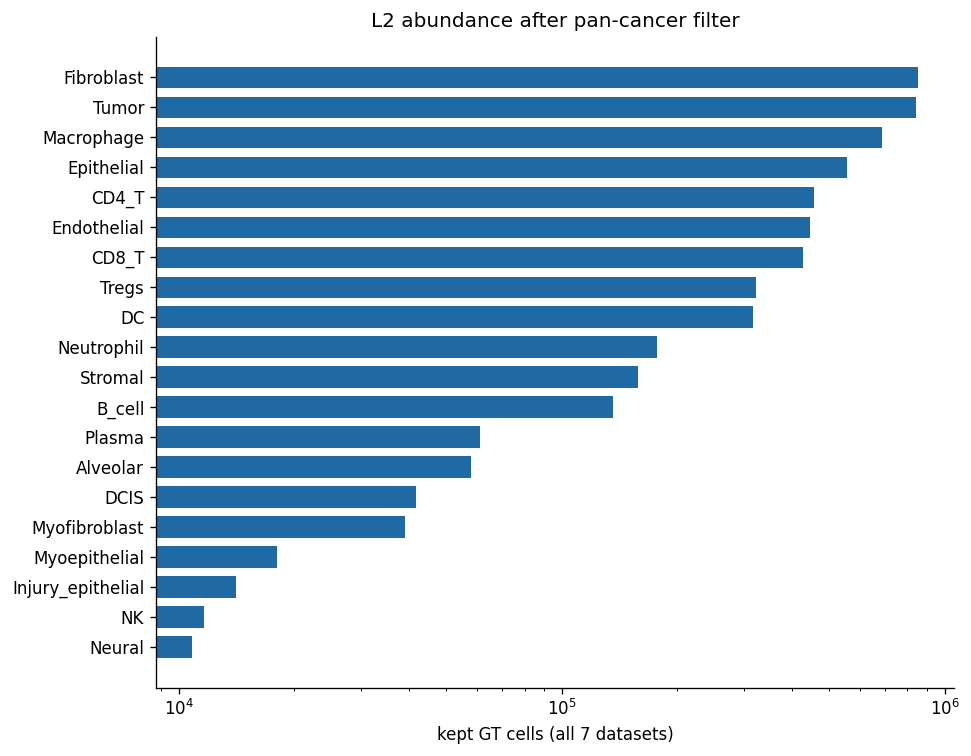

In [6]:
l2_order = pc["L2"].astype(str).tolist()
l2 = (
    kept.groupby(["dataset", "L2"], observed=True)["n"].sum()
    .unstack("dataset")
    .reindex(index=l2_order, columns=DATASETS)
    .fillna(0)
)
l2["total"] = l2.sum(axis=1)
display(l2.astype(int))

fig, ax = plt.subplots(figsize=(9.2, 7.2))
mat = l2[DATASETS].to_numpy(dtype=float)
mat_plot = np.log10(mat + 1)
im = ax.imshow(mat_plot, cmap="YlGnBu", aspect="auto")
ax.set_xticks(range(len(DATASETS)))
ax.set_xticklabels(DATASETS)
ax.set_yticks(range(len(l2_order)))
ax.set_yticklabels(l2_order)
ax.set_title("L2 cell counts (log10 n+1) — pan-cancer kept cells")
cb = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
cb.set_label("log10(n + 1)")
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        n = mat[i, j]
        if n <= 0:
            continue
        txt = f"{n/1e6:.1f}M" if n >= 1e6 else (f"{n/1e3:.0f}k" if n >= 1000 else f"{int(n)}")
        ax.text(j, i, txt, ha="center", va="center", fontsize=7,
                color="white" if mat_plot[i, j] > 3.2 else "#222")
fig.tight_layout()
fig.savefig(FIG / "04_L2_heatmap.png", bbox_inches="tight", facecolor="white")
plt.show()

fig, ax = plt.subplots(figsize=(8.2, 6.4))
totals = l2["total"].sort_values(ascending=True)
ax.barh(totals.index, totals.values, color="#1f6aa5", height=0.72)
ax.set_xlabel("kept GT cells (all 7 datasets)")
ax.set_title("L2 abundance after pan-cancer filter")
ax.set_xscale("log")
fig.tight_layout()
fig.savefig(FIG / "05_L2_totals.png", bbox_inches="tight", facecolor="white")
plt.show()


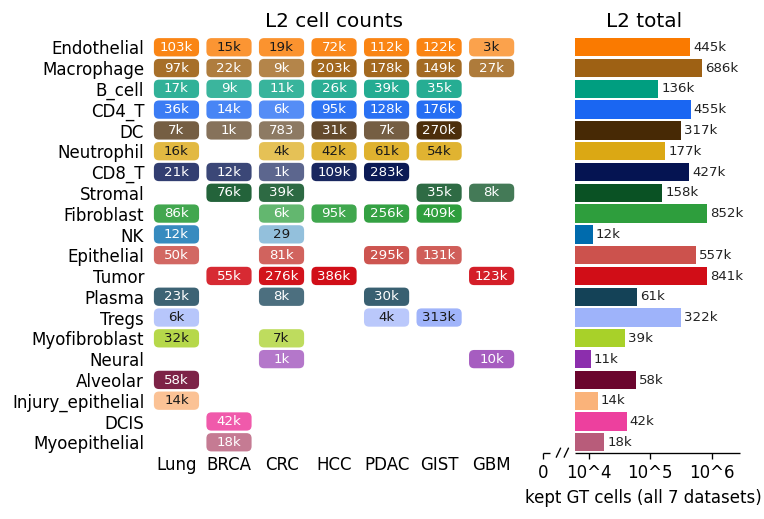

In [7]:
import sys
from matplotlib.patches import FancyBboxPatch
from matplotlib.transforms import blended_transform_factory
if str(HERE.parent) not in sys.path:
    sys.path.insert(0, str(HERE.parent))
from plotting_palettes import get_palette

L2_PAL = get_palette("pancancer", "fine")
# Same axes as the L2 presence heatmap: columns are the 7 training datasets,
# rows are sorted by how many of those datasets contain the class.
col_order = ["Lung", "BRCA", "CRC", "HCC", "PDAC", "GIST", "GBM"]
l2_axis = [
    "Endothelial", "Macrophage", "B_cell", "CD4_T", "DC", "Neutrophil",
    "CD8_T", "Stromal", "Fibroblast", "NK", "Epithelial", "Tumor",
    "Plasma", "Tregs", "Myofibroblast", "Neural", "Alveolar",
    "Injury_epithelial", "DCIS", "Myoepithelial",
]
l2_side = l2.reindex(l2_axis)
mat = l2_side[col_order].to_numpy(dtype=float)
totals = l2_side["total"].to_numpy(dtype=float)
bar_colors = [L2_PAL[name] for name in l2_axis]

def _l2_tint(name, n, n_max):
    r, g, b = L2_PAL[name][:3]
    if n <= 0:
        return None
    t = np.log10(n + 1) / np.log10(n_max + 1)
    t = 0.22 + 0.78 * float(t)
    rgb = ((1 - t) + t * r, (1 - t) + t * g, (1 - t) + t * b)
    lum = 0.299 * rgb[0] + 0.587 * rgb[1] + 0.114 * rgb[2]
    return rgb, ("white" if lum < 0.62 else "#1a1a1a")

n_max = float(mat.max())
n_rows, n_cols = mat.shape
cell_h, cell_w = 0.88, 0.86

plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42
plt.rcParams["pdf.use14corefonts"] = True
fig = plt.figure(figsize=(6.5, 4.5), facecolor="white")
gs = fig.add_gridspec(1, 2, width_ratios=[1.72, 1.0], wspace=0.05)
ax = fig.add_subplot(gs[0, 0])
axb = fig.add_subplot(gs[0, 1], sharey=ax)
ax.set_facecolor("white")
ax.set_xlim(-0.55, n_cols - 0.45)
ax.set_ylim(n_rows - 0.5, -0.5)
fig.canvas.draw()
p0 = ax.transData.transform((0, 0))
sx = abs(ax.transData.transform((1, 0))[0] - p0[0])
sy = abs(ax.transData.transform((0, 1))[1] - p0[1])
mut = sx / sy
radius = 0.28 * min(cell_w, cell_h / mut)
boxstyle = f"round,pad=0,rounding_size={radius:.4f}"

for i in range(n_rows):
    for j in range(n_cols):
        painted = _l2_tint(l2_axis[i], mat[i, j], n_max)
        if painted is None:
            continue
        rgb, ink = painted
        ax.add_patch(FancyBboxPatch(
            (j - cell_w / 2, i - cell_h / 2), cell_w, cell_h,
            boxstyle=boxstyle, mutation_aspect=mut,
            facecolor=rgb, edgecolor="none", zorder=2,
        ))
        n = mat[i, j]
        txt = f"{n/1e6:.1f}M" if n >= 1e6 else (f"{n/1e3:.0f}k" if n >= 1000 else f"{int(n)}")
        ax.text(j, i, txt, ha="center", va="center", fontsize=8, color=ink, zorder=3)

ax.set_xticks(range(n_cols))
ax.set_xticklabels(col_order)
ax.set_yticks(range(n_rows))
ax.set_yticklabels(l2_axis)
ax.set_title("L2 cell counts")
ax.tick_params(length=0, pad=2)
for sp in ax.spines.values():
    sp.set_visible(False)

pos = totals[totals > 0]
left = float(pos.min() * 0.55)
log_left = np.log10(left)
log_right = np.log10(float(totals.max()) * 3.4)
u_axis_start, u_axis_end = 0.16, 1.0

def _u(v):
    t = (np.log10(v) - log_left) / (log_right - log_left)
    return u_axis_start + t * (u_axis_end - u_axis_start)

u_right = _u(np.maximum(totals, left))
axb.barh(
    range(n_rows), np.maximum(u_right - u_axis_start, 0), left=u_axis_start,
    color=bar_colors, height=cell_h,
)
axb.set_xlim(-0.04, 1.06)
tick_vals = [0.0]
tick_labs = ["0"]
for k in range(int(np.ceil(log_left)), int(np.floor(log_right)) + 1):
    tick_vals.append(_u(10 ** k))
    tick_labs.append(f"10^{k}")
axb.set_xticks(tick_vals)
axb.set_xticklabels(tick_labs)
axb.spines["bottom"].set_visible(False)
spine = blended_transform_factory(axb.transData, axb.transAxes)
spine_kw = dict(transform=spine, color="black", lw=0.8, clip_on=False, zorder=5, solid_capstyle="butt")
axb.plot([0.0, 0.035], [0, 0], **spine_kw)
axb.plot([u_axis_start, u_axis_end], [0, 0], **spine_kw)
gap_mid = (0.035 + u_axis_start) / 2
for dx in (-0.02, 0.02):
    axb.plot([gap_mid + dx - 0.012, gap_mid + dx + 0.012], [-0.012, 0.012], **spine_kw)
for i, n in enumerate(totals):
    if n <= 0:
        continue
    txt = f"{n/1e6:.1f}M" if n >= 1e6 else (f"{n/1e3:.0f}k" if n >= 1000 else f"{int(n)}")
    axb.text(_u(n) + 0.015, i, txt, va="center", ha="left", fontsize=8, color="#222")
axb.set_xlabel("kept GT cells (all 7 datasets)")
axb.set_title("L2 total")
axb.tick_params(axis="y", left=False, labelleft=False)
axb.spines["top"].set_visible(False)
axb.spines["right"].set_visible(False)
axb.spines["left"].set_visible(False)
fig.savefig(FIG / "04b_L2_heatmap_totals.png", bbox_inches="tight", facecolor="white")
fig.savefig(FIG / "04b_L2_heatmap_totals.pdf", bbox_inches="tight", facecolor="white")
plt.show()


## 6. Per-dataset L2 composition (kept)


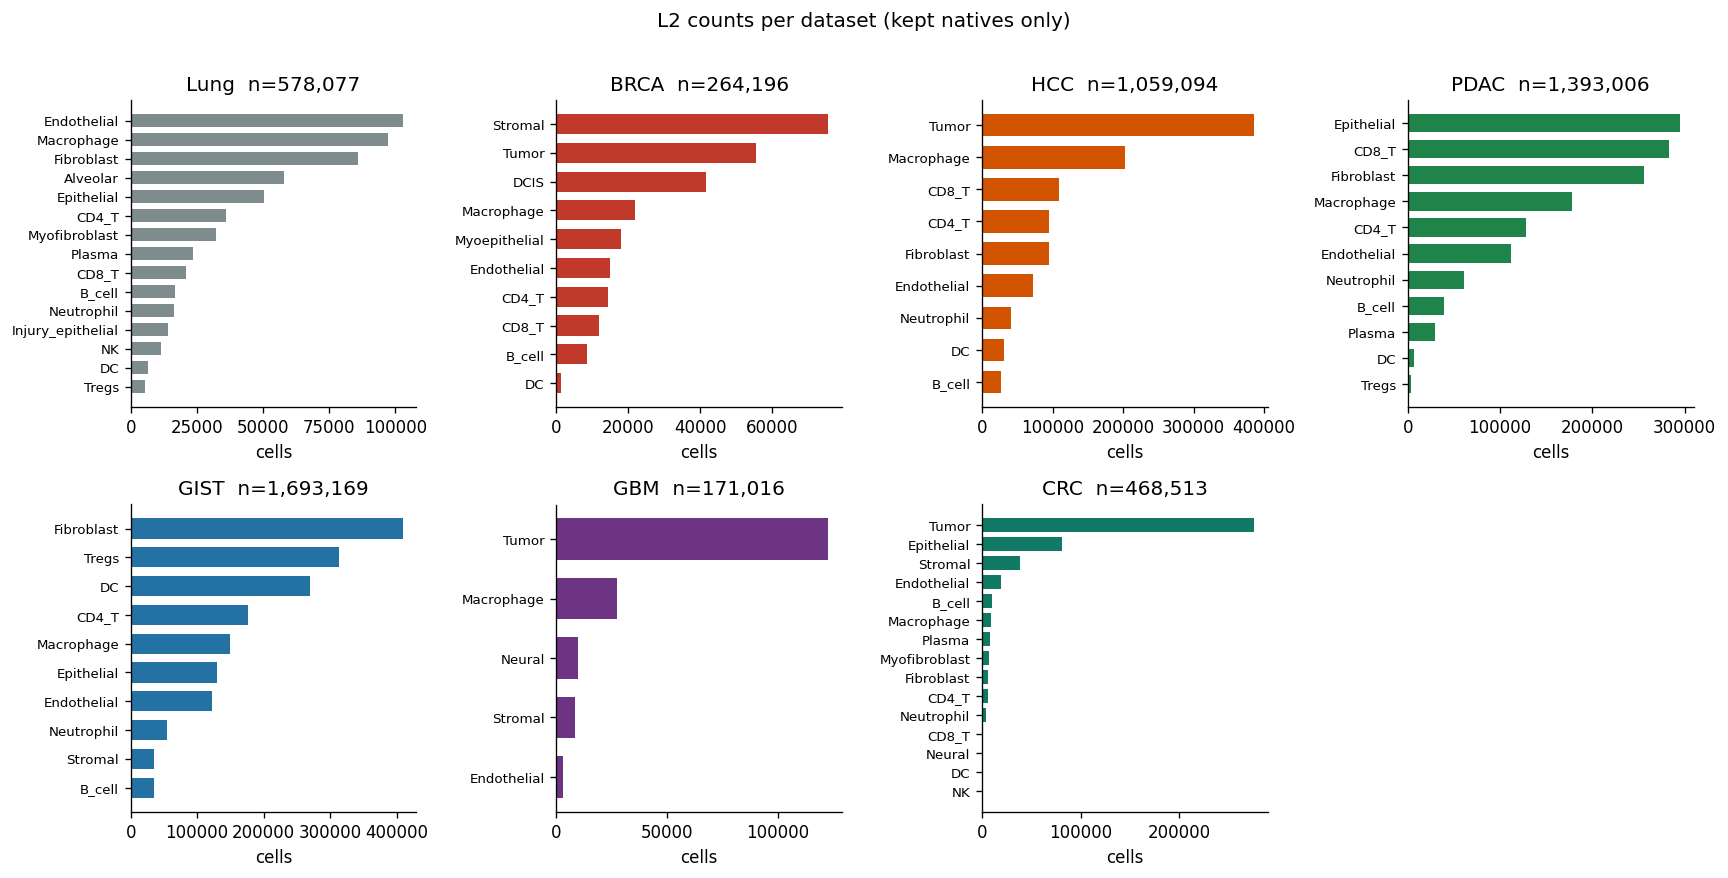

figures → /nobackup2/users/lingyu/Python/Hist2Pheno/code/Hist2Pheno_pkg/dataset/figures_pancancer_counts
  01_kept_vs_dropped.png
  02_L1_counts.png
  03_L12_counts.png
  04_L2_heatmap.png
  04b_L2_heatmap_totals.png
  05_L2_totals.png
  06_L2_by_dataset.png


In [8]:
fig, axes = plt.subplots(2, 4, figsize=(14.5, 7.2), sharey=False)
axes = axes.ravel()
for ax, ds in zip(axes, DATASETS):
    s = l2[ds]
    s = s[s > 0].sort_values(ascending=True)
    ax.barh(s.index, s.values, color=DS_COLOR[ds], height=0.7)
    ax.set_title(f"{ds}  n={int(s.sum()):,}")
    ax.set_xlabel("cells")
    ax.tick_params(axis="y", labelsize=8)
axes[-1].axis("off")
fig.suptitle("L2 counts per dataset (kept natives only)", y=1.01)
fig.tight_layout()
fig.savefig(FIG / "06_L2_by_dataset.png", bbox_inches="tight", facecolor="white")
plt.show()

print("figures →", FIG)
for p in sorted(FIG.glob("*.png")):
    print(" ", p.name)
